# 13 — Player archetypes: what kinds of players are there?

**Question.** Can we sort player-seasons into recognisable **archetypes** (creator big, 3-and-D wing, rim-runner, on-ball scorer…) by *how* they play, not *how well*? Then: who is similar to whom at the same career stage, and which archetype moves lead to stardom?

**This first step (13A) does no clustering.** It sets out the style measures and how they behave, so the decisions below can be made first:
1. **Which measures define style.**
2. **Era adjustment:** compare each player with his own season, or on one scale across 2011-26?
3. **The unit:** each player-season, or career stages?
4. **How many archetypes, and hard or soft membership?**

And before clustering, **you write down the archetypes you expect**, so we can compare them with what the data finds.

**Style, not quality.** Shooting percentages, plus-minus, net rating and all-in-one ratings are left out on purpose: a good and a bad rim-runner should land in the same archetype.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, SURFACE, apply_style
from unicorn.raw import PROJECT_ROOT

warnings.filterwarnings("ignore")
apply_style()
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
MIN_MINUTES = 500
P = ps[ps["min"] >= MIN_MINUTES].copy()
print(f"{len(ps):,} player-seasons 2011-12 → 2025-26; {len(P):,} with {MIN_MINUTES}+ minutes "
      f"({P.groupby('season').size().min()}–{P.groupby('season').size().max()} a season)")

7,889 player-seasons 2011-12 → 2025-26; 5,353 with 500+ minutes (331–378 a season)


## 13A — Candidate style measures

Grouped by what they describe. Every one is a **share or rate**, so it describes the shape of a player's game rather than how much he plays.

In [2]:
STYLE = {
    "where he shoots": {"rim_rate": "shots at the rim (share of shots)", "paint_non_ra_rate": "paint, not at the rim", "mid_rate": "mid-range",
                        "fg3a_rate": "three-pointers", "corner3_share": "corner threes (share of his threes)", "fta_rate": "free throws per shot"},
    "how he creates": {"usg_pct": "usage (share of team plays he finishes)", "pct_uast_fgm": "unassisted makes (self-created)",
                       "ast_pct": "assist rate", "pct_pts_fb": "fast-break points (share of his points)"},
    "rebounding": {"oreb_pct": "offensive rebound rate", "dreb_pct": "defensive rebound rate"},
    "defence (box score)": {"blk_per100": "blocks per 100 possessions", "stl_per100": "steals per 100 possessions", "pf_per36": "fouls per 36"},
    "body (optional)": {"height_in": "height", "weight_lb": "weight"},
}
FEATURES = [c for g in STYLE.values() for c in g]
LABEL = {c: lab for g in STYLE.values() for c, lab in g.items()}
desc = P[FEATURES].describe(percentiles=[0.1, 0.5, 0.9]).T[["mean", "10%", "50%", "90%"]]
desc.insert(0, "group", [g for g, d in STYLE.items() for _ in d]); desc.insert(1, "measure", [LABEL[c] for c in desc.index])
print("missing values:", P[FEATURES].isna().sum()[lambda s: s > 0].to_dict() or "none")
desc.round(3)

missing values: {'corner3_share': 227, 'weight_lb': 2}


,group,measure,mean,10%,50%,90%
rim_rate,where he shoots,shots at the rim (share of shots),0.328,0.136,0.292,0.589
paint_non_ra_rate,where he shoots,"paint, not at the rim",0.162,0.068,0.150,0.271
mid_rate,where he shoots,mid-range,0.165,0.031,0.139,0.339
fg3a_rate,where he shoots,three-pointers,0.345,0.009,0.366,0.610
corner3_share,where he shoots,corner threes (share of his threes),0.274,0.072,0.246,0.500
fta_rate,where he shoots,free throws per shot,0.256,0.119,0.237,0.413
usg_pct,how he creates,usage (share of team plays he finishes),0.188,0.127,0.181,0.260
pct_uast_fgm,how he creates,unassisted makes (self-created),0.363,0.160,0.335,0.613
ast_pct,how he creates,assist rate,0.145,0.058,0.116,0.278
pct_pts_fb,how he creates,fast-break points (share of his points),0.125,0.049,0.120,0.206


### Why era adjustment is a real decision

The league changed a lot from 2011-12 to 2025-26. If we cluster on raw numbers, a 2013 big man and a 2025 big man could land in different archetypes only because of the era.

,fg3a_rate,mid_rate,rim_rate,ast_pct,pct_uast_fgm
season_start,,,,,
2011,0.234,0.286,0.300,0.109,0.371
2015,0.296,0.210,0.306,0.107,0.356
2019,0.401,0.100,0.299,0.112,0.326
2023,0.419,0.076,0.277,0.130,0.316
2025,0.440,0.068,0.269,0.132,0.316


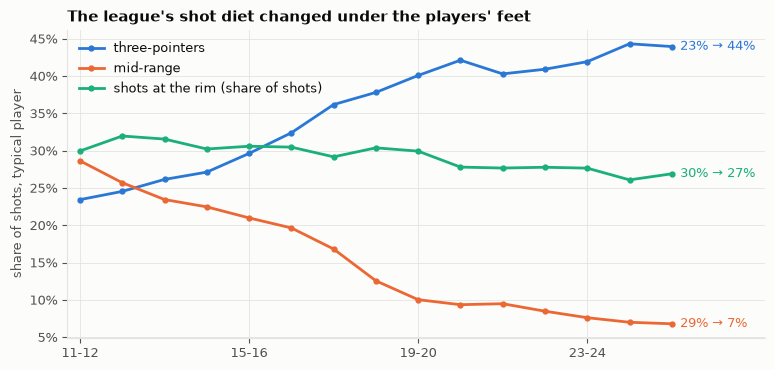

In [3]:
drift = P.groupby("season_start")[["fg3a_rate", "mid_rate", "rim_rate", "ast_pct", "pct_uast_fgm"]].median()
fig, ax = plt.subplots(figsize=(9, 4))
for col, c in zip(["fg3a_rate", "mid_rate", "rim_rate"], [BLUE, ORANGE, SERIES[2]]):
    ax.plot(drift.index, drift[col], color=c, marker="o", markersize=3.5, label=LABEL[col])
    ax.annotate(f"{drift[col].iloc[0]:.0%} → {drift[col].iloc[-1]:.0%}", (drift.index[-1], drift[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=c)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_xlim(drift.index[0] - 0.3, drift.index[-1] + 2.2)
ax.set_xticks([2011, 2015, 2019, 2023], ["11-12", "15-16", "19-20", "23-24"])
ax.set_ylabel("share of shots, typical player"); ax.legend(frameon=False, loc="upper left")
ax.set_title("The league's shot diet changed under the players' feet", loc="left")
fig.savefig(FIG_DIR / "13_style_drift.png", dpi=150, bbox_inches="tight")
drift.round(3).iloc[[0, 4, 8, 12, 14]]

### Which measures overlap?

Pairs that move together mostly say the same thing twice. That gives them double weight in a clustering unless we drop or combine one.

In [4]:
z = P.groupby("season_start")[FEATURES].transform(lambda s: (s - s.mean()) / s.std())   # season-relative
corr = z.corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().rename("correlation").reset_index()
         .assign(strength=lambda d: d["correlation"].abs()).sort_values("strength", ascending=False).head(10))
pairs["pair"] = pairs["level_0"].map(LABEL) + "  ↔  " + pairs["level_1"].map(LABEL)
pairs.set_index("pair")[["correlation"]].round(2)

,correlation
pair,
height ↔ weight,0.81
shots at the rim (share of shots) ↔ three-pointers,-0.75
defensive rebound rate ↔ height,0.75
offensive rebound rate ↔ defensive rebound rate,0.74
shots at the rim (share of shots) ↔ offensive rebound rate,0.72
offensive rebound rate ↔ height,0.71
defensive rebound rate ↔ weight,0.71
unassisted makes (self-created) ↔ assist rate,0.70
blocks per 100 possessions ↔ height,0.68


### A first look at the space (no clusters yet)

Every 2025-26 player with 1,000+ minutes, placed by the two main directions of variation in the season-relative style measures (principal components, body measures excluded). Well-known players are labelled to show what each direction means.

In [5]:
from numpy.linalg import svd
NO_BODY = [c for c in FEATURES if c not in STYLE["body (optional)"]]
cur = P[(P["season_start"] == 2025) & (P["min"] >= 1000)].copy()
Zc = z.loc[cur.index, NO_BODY].fillna(0).to_numpy()
Zc = Zc - Zc.mean(axis=0)
U, S, Vt = svd(Zc, full_matrices=False)
share = S ** 2 / (S ** 2).sum()
cur["pc1"], cur["pc2"] = U[:, 0] * S[0], U[:, 1] * S[1]
if cur.loc[cur["player_name"] == "Rudy Gobert", "pc1"].mean() < 0:      # orient: bigs to the right
    cur["pc1"] *= -1; Vt[0] *= -1
if cur.loc[cur["player_name"] == "Shai Gilgeous-Alexander", "pc2"].mean() < 0:  # creators up
    cur["pc2"] *= -1; Vt[1] *= -1
loadings = pd.DataFrame(Vt[:2].T, index=[LABEL[c] for c in NO_BODY], columns=["direction 1", "direction 2"])
print(f"direction 1 explains {share[0]:.0%} of the variation, direction 2 {share[1]:.0%}")
loadings.round(2).sort_values("direction 1")

direction 1 explains 29% of the variation, direction 2 25%


,direction 1,direction 2
mid-range,-0.31,0.21
three-pointers,-0.26,-0.37
assist rate,-0.26,0.32
usage (share of team plays he finishes),-0.25,0.36
unassisted makes (self-created),-0.19,0.39
fast-break points (share of his points),-0.12,-0.19
steals per 100 possessions,-0.01,-0.05
"paint, not at the rim",-0.00,0.35
free throws per shot,0.14,0.32
corner threes (share of his threes),0.22,-0.24


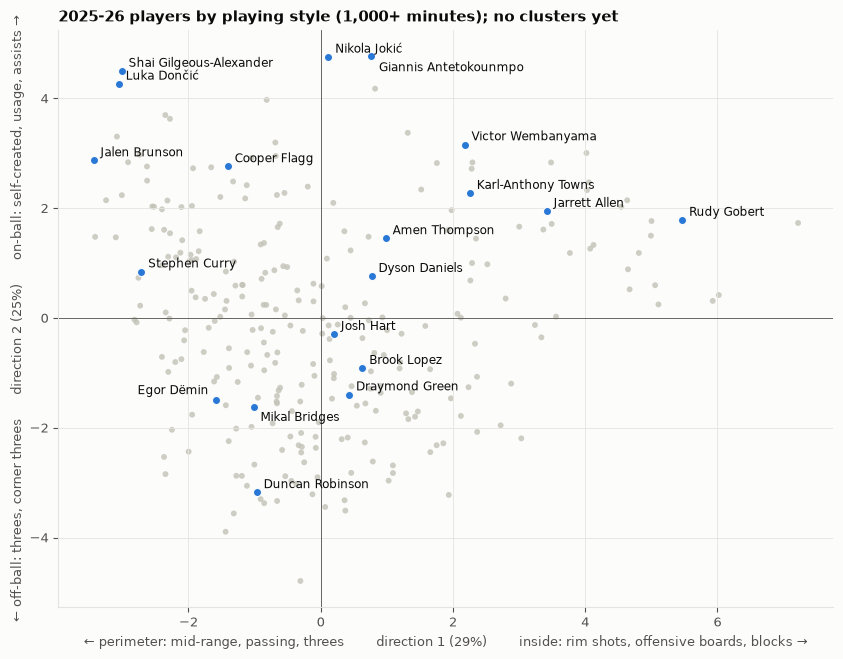

In [6]:
SHOW = ["Nikola Jokić", "Victor Wembanyama", "Rudy Gobert", "Giannis Antetokounmpo", "Shai Gilgeous-Alexander", "Luka Dončić",
        "Stephen Curry", "Jalen Brunson", "Dyson Daniels", "Mikal Bridges", "Jarrett Allen", "Karl-Anthony Towns", "Draymond Green",
        "Josh Hart", "Duncan Robinson", "Brook Lopez", "Ty Jerome", "Amen Thompson", "Egor Dëmin", "Cooper Flagg"]
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.scatter(cur["pc1"], cur["pc2"], s=18, color=MUTED, alpha=0.8, edgecolor="none")
lab = cur[cur["player_name"].isin(SHOW)]
ax.scatter(lab["pc1"], lab["pc2"], s=34, color=BLUE, edgecolor=SURFACE, linewidth=0.8, zorder=3)
for _, r in lab.iterrows():
    dx, dy, ha = {"Giannis Antetokounmpo": (6, -11, "left"), "Mikal Bridges": (5, -10, "left"), "Egor Dëmin": (-5, 4, "right")}.get(r["player_name"], (5, 3, "left"))
    ax.annotate(r["player_name"], (r["pc1"], r["pc2"]), xytext=(dx, dy), textcoords="offset points", fontsize=8.5, color=INK, ha=ha)
# plain names for the two directions, read off the loadings table above
ax.set_xlabel(f"← perimeter: mid-range, passing, threes        direction 1 ({share[0]:.0%})        inside: rim shots, offensive boards, blocks →")
ax.set_ylabel(f"← off-ball: threes, corner threes      direction 2 ({share[1]:.0%})      on-ball: self-created, usage, assists →")
ax.axhline(0, color=INK2, linewidth=0.6); ax.axvline(0, color=INK2, linewidth=0.6)
ax.set_title("2025-26 players by playing style (1,000+ minutes); no clusters yet", loc="left")
fig.savefig(FIG_DIR / "13_style_map_2025_26.png", dpi=150, bbox_inches="tight")

### 13A: decisions for you (before any clustering)

**0. Your expected archetypes.** Write down the types you think exist (names and a one-line description each). We compare them with what the data finds, which is the most interesting part of the study.

**1. Which measures define style?** Default: the 15 above (where he shoots, how he creates, rebounding, box-score defence).
- **Body (height, weight): in or out?** In: archetypes partly mean size ("big"). Out: archetypes are purely about the game, and we can then check *afterwards* which types are size-bound (a 6'6" rim-runner would show up as unusual, which ties in with the unicorn study).
- **Overlapping pairs** (table above): keep both, drop one, or combine.

**2. Era adjustment.**
- **Season-relative (my recommendation):** each player compared with his own season, so "a big who shoots threes for 2014" counts as stretchy even if the 2025 bar is higher.
- **One scale:** archetypes drift over time (more 2025 players in shooting types), which is real history but mixes era into type.

**3. The unit.** Each player-season (a player can change type from year to year, which item 4 of the plan needs) vs a career summary. Recommendation: player-seasons with 500+ minutes.

**4. How many types, and hard or soft?**
- I will show fit statistics for 4–14 types, but the final number should be the one where every type has a name you'd use. My guess: 8–12.
- **Hard** (each season in one type) is easier to read. **Soft** (e.g. "70% rim-runner, 30% stretch big") is truer for in-between players. A common compromise: soft fit, report the main type plus a second type when it holds 30%+.